# IonQ - Learning and Testing

## 1. Imports

In [1]:
from qiskit import QuantumCircuit, transpile
from qiskit_ionq import IonQProvider
from qiskit.circuit import Gate
from dotenv import load_dotenv
import os

import pprint

In [2]:
# Environment variable are loaded.
load_dotenv()

True

## 2. Auxiliar Functions

In [3]:
# This function is defined so the output mode and style are centralized.
def draw_circuit(qc: QuantumCircuit):
    return qc.draw(output='mpl', style='bw')

In [4]:
def transform_native_to_quantum_circuit(native):
    data = native.get("circuit", native.get("input", {}).get("circuit", []))
    n = native.get("qubits", native.get("input", {}).get("qubits"))

    qc = QuantumCircuit(n)

    for op in data:
        name = op["gate"]
        targets = op.get("targets", [op.get("target")])

        params = []
        if "phase" in op:
            params.append(op["phase"])
        if "phases" in op:
            params.extend(op["phases"])
        if "angle" in op:
            params.append(op["angle"])

        if name == "measure":
            qc.measure(targets[0], targets[0])
        else:
            qc.append(
                Gate(name.upper(), len(targets), params),
                targets
            )

    return qc

Provider initialization (no API key is required if compiled locally).

In [5]:
provider = IonQProvider(token=os.getenv("IONQ_API_KEY"))
backend = provider.get_backend('ionq_simulator')

/home/iroumec/Documents/Quantum-Computing-Learning/.venv/lib/python3.13/site-packages/qiskit_ionq/ionq_backend.py:129: IonQTranspileLevelWarning: Transpiler default optimization_level=2. IonQ (QIS) recommends 0-1 to avoid aggressive re-synthesis; use transpile(..., optimization_level=1).
  warn_bad_transpile_level()


Bell state quantum circuit construction.

In [6]:
qc = QuantumCircuit(2, 2)
qc.h(0)
qc.cx(0, 1)
qc.measure([0, 1], [0, 1])

Bell state quantum circuit visualization.

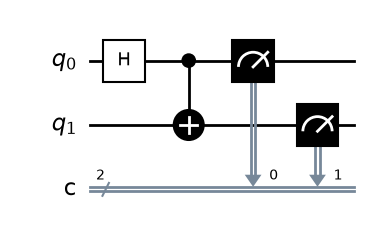

In [7]:
draw_circuit(qc)

Circuit is transpiled to IonQ native base.

Native circuit in IonQ:


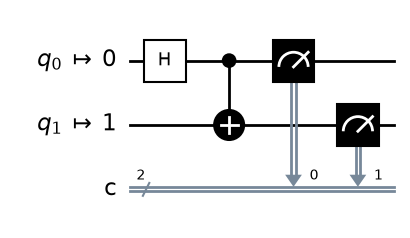

In [8]:
qc_ionq = transpile(
    qc, 
    backend=backend, 
    optimization_level=1
)

print("Native circuit in IonQ:")
draw_circuit(qc_ionq)

In [9]:
job = backend.run(
    qc,
    dry_run=True,
    job_settings={"compilation": {"service_version": "v0.4"}}
)

job.wait_for_final_state()

native = job.compiled_circuit(lang="native")

pprint.pp(native)

OrderedDict([('qubits', 2),
             ('circuit',
              [OrderedDict({'gate': 'gpi2', 'phase': 0.75, 'target': 0}),
               OrderedDict({'gate': 'gpi2', 'phase': 0.75, 'target': 1}),
               OrderedDict({'gate': 'zz', 'targets': [0, 1], 'angle': 0.25}),
               OrderedDict({'gate': 'gpi2', 'phase': 0.5, 'target': 1})]),
             ('gateset', 'native')])


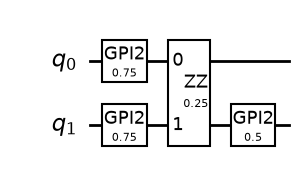

In [10]:
native_qc = transform_native_to_quantum_circuit(native)

draw_circuit(native_qc)

La compuerta cuántica XX aplica una interacción entre dos qubits equivalente a X⊗X cuando se trata de la operación Pauli-XX. En circuitos cuánticos también suele usarse la compuerta de rotación R
XX
	​

(θ). Veamos un ejemplo con Qiskit que muestra el circuito y su resultadoXX gate:

In [17]:

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt
import numpy as np

qc = QuantumCircuit(2, 2)

qc.h(0)
qc.h(1)
qc.rxx(np.pi / 2, 0, 1)
qc.measure([0, 1], [0, 1])

print(qc.draw())

# Simulate the circuit
from qiskit_aer import AerSimulator

simulator = AerSimulator()
result = simulator.run(qc, shots=1024).result()
counts = result.get_counts()

print(counts)
plot_histogram(counts)
plt.show()

     ┌───┐┌───────────┐┌─┐   
q_0: ┤ H ├┤0          ├┤M├───
     ├───┤│  Rxx(π/2) │└╥┘┌─┐
q_1: ┤ H ├┤1          ├─╫─┤M├
     └───┘└───────────┘ ║ └╥┘
c: 2/═══════════════════╩══╩═
                        0  1 
{'11': 241, '10': 270, '00': 256, '01': 257}


La compuerta cuántica XX aplica una interacción entre dos qubits equivalente a X⊗XX\otimes XX⊗X cuando se trata de la operación Pauli-XX. En circuitos cuánticos también suele usarse la compuerta de rotación RXX(θ)R_{XX}(\theta)RXX(θ). Veamos un ejemplo con Qiskit que muestra el circuito y su resultado.

## 1. Circuito con la compuerta XX

Partimos del estado inicial ∣00⟩|00\rangle∣00⟩, aplicamos RXX(π/2)R_{XX}(\pi/2)RXX(π/2) y medimos ambos qubits.

Python

Run

```
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt
import numpy as np

qc = QuantumCircuit(2, 2)

qc.h(0)
qc.h(1)
qc.rxx(np.pi / 2, 0, 1)
qc.measure([0, 1], [0, 1])

print(qc.draw())

# Simulate the circuit
from qiskit_aer import AerSimulator

simulator = AerSimulator()
result = simulator.run(qc, shots=1000).result()
counts = result.get_counts()

print(counts)
plot_histogram(counts)
plt.show()
```

## 2. ¿Qué resultado esperar?

La matriz de la compuerta de rotación es

RXX(θ)=(cos⁡θ200−isin⁡θ20cos⁡θ2−isin⁡θ200−isin⁡θ2cos⁡θ20000cos⁡θ2)R_{XX}(\theta)= \begin{pmatrix} \cos\frac{\theta}{2}&0&0&-i\sin\frac{\theta}{2}\\ 0&\cos\frac{\theta}{2}&-i\sin\frac{\theta}{2}&0\\ 0&-i\sin\frac{\theta}{2}&\cos\frac{\theta}{2}&0\\ 0&0&0&\cos\frac{\theta}{2} \end{pmatrix}RXX(θ)=cos2θ0000cos2θ−isin2θ00−isin2θcos2θ0−isin2θ00cos2θ

Para θ=π/2\theta=\pi/2θ=π/2, y con ambos qubits inicialmente en ∣+⟩|+\rangle∣+⟩, el estado final es

∣ψ⟩=12(∣00⟩−i∣01⟩−i∣10⟩+∣11⟩)|\psi\rangle = \frac{1}{2}\left( |00\rangle-i|01\rangle-i|10\rangle+|11\rangle \right)∣ψ⟩=21(∣00⟩−i∣01⟩−i∣10⟩+∣11⟩)

Por lo tanto, las probabilidades de medición son:

| Resultado | Probabilidad |
| --------- | ------------ |
| `00`      | 25 %         |
| `01`      | 25 %         |
| `10`      | 25 %         |
| `11`      | 25 %         |

Importante: en este ejemplo las cuatro probabilidades son iguales. Para observar con mayor claridad el efecto de XX, también podés partir de ∣00⟩|00\rangle∣00⟩ sin aplicar las compuertas Hadamard; en ese caso, RXX(π/2)R_{XX}(\pi/2)RXX(π/2) genera una superposición entre ∣00⟩|00\rangle∣00⟩ y ∣11⟩|11\rangle∣11⟩, con un 50 % de probabilidad para cada resultado.


Este ejemplo muestra cómo la compuerta RXX(π/2)R_{XX}(\pi/2)RXX(π/2) genera entrelazamiento entre dos qubits a partir del estado ∣00⟩|00\rangle∣00⟩.

Python

Run

```
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import numpy as np
import matplotlib.pyplot as plt

qc = QuantumCircuit(2, 2)
qc.rxx(np.pi / 2, 0, 1)
qc.measure([0, 1], [0, 1])

print(qc.draw())

result = AerSimulator().run(qc, shots=1000).result()
counts = result.get_counts()

print(counts)
plot_histogram(counts)
plt.show()
```

Resultado esperado:

* `00`: ~50 %

* `11`: ~50 %

* `01` y `10`: 0 %

La compuerta crea el estado

∣ψ⟩=∣00⟩−i∣11⟩2|\psi\rangle=\frac{|00\rangle-i|11\rangle}{\sqrt{2}}∣ψ⟩=2∣00⟩−i∣11⟩

Al medir, ambos qubits dan siempre el mismo resultado. Esa correlación es una manifestación del entrelazamiento generado por RXX(π/2)R_{XX}(\pi/2)RXX(π/2).


In [20]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import numpy as np
import matplotlib.pyplot as plt

qc = QuantumCircuit(2, 2)
qc.rxx(np.pi / 2, 0, 1)
qc.measure([0, 1], [0, 1])

print(qc.draw())

result = AerSimulator().run(qc, shots=1000).result()
counts = result.get_counts()

print(counts)
plot_histogram(counts)
plt.show()

     ┌───────────┐┌─┐   
q_0: ┤0          ├┤M├───
     │  Rxx(π/2) │└╥┘┌─┐
q_1: ┤1          ├─╫─┤M├
     └───────────┘ ║ └╥┘
c: 2/══════════════╩══╩═
                   0  1 
{'11': 489, '00': 511}


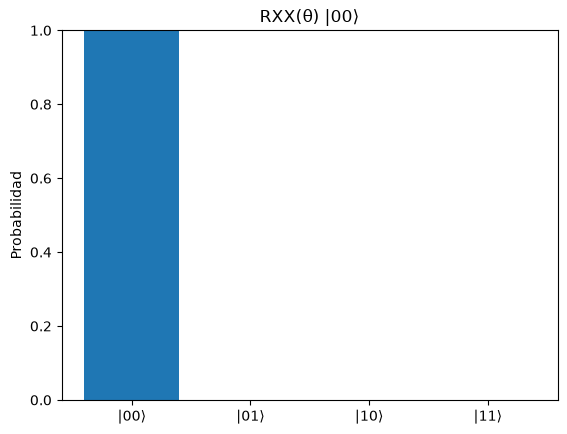

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from qiskit.quantum_info import Statevector

theta = np.linspace(0, np.pi, 100)
states = [
    Statevector.from_label("00").evolve(
        __import__("qiskit").QuantumCircuit(2)
    )
]

# RXX(theta)|00> = cos(theta/2)|00> - i sin(theta/2)|11>
p00 = np.cos(theta / 2) ** 2
p11 = np.sin(theta / 2) ** 2

fig, ax = plt.subplots()
bars = ax.bar(["|00⟩", "|01⟩", "|10⟩", "|11⟩"], [1, 0, 0, 0])
ax.set_ylim(0, 1)
ax.set_ylabel("Probabilidad")
title = ax.set_title("RXX(θ) |00⟩")

def update(i):
    probs = [p00[i], 0, 0, p11[i]]
    for bar, p in zip(bars, probs):
        bar.set_height(p)
    title.set_text(f"RXX(θ) |00⟩ — θ = {theta[i]:.2f} rad")
    return (*bars, title)

ani = FuncAnimation(fig, update, frames=len(theta), interval=50, blit=False)
plt.show()

Sí, pero hay una distinción importante: la compuerta HHH (Hadamard) y la compuerta XXX hacen cosas distintas en la esfera de Bloch.

## Equivalencias

| Estado inicial                | Compuerta | Estado final     |
| ----------------------------- | --------- | ---------------- |
| ∣0⟩\|0\rangle∣0⟩ (polo norte) | HHH       | ∣+⟩\|+\rangle∣+⟩ |
| ∣1⟩\|1\rangle∣1⟩ (polo sur)   | HHH       | ∣−⟩\|-\rangle∣−⟩ |
| ∣+⟩\|+\rangle∣+⟩ (eje +X)     | HHH       | ∣0⟩\|0\rangle∣0⟩ |
| ∣−⟩\|-\rangle∣−⟩ (eje −X)     | HHH       | ∣1⟩\|1\rangle∣1⟩ |
| ∣0⟩\|0\rangle∣0⟩              | XXX       | ∣1⟩\|1\rangle∣1⟩ |
| ∣+⟩\|+\rangle∣+⟩              | XXX       | ∣+⟩\|+\rangle∣+⟩ |

Por tanto, sí: HHH lleva ∣0⟩|0\rangle∣0⟩ a ∣+⟩|+\rangle∣+⟩ y ∣+⟩|+\rangle∣+⟩ a ∣0⟩|0\rangle∣0⟩. Es una operación reversible y H2=IH^2=IH2=I.

## ¿Qué hace cada compuerta?

* HHH: intercambia los ejes ZZZ y XXX de la esfera de Bloch (y cambia el signo del eje YYY).

* XXX: rota 180° alrededor del eje XXX.

* YYY: rota 180° alrededor del eje YYY.

* ZZZ: rota 180° alrededor del eje ZZZ.

La clave es que HHH no es simplemente «crear superposición»: también transforma estados de superposición en estados de la base computacional.


La compuerta RXX(θ)R_{XX}(\theta)RXX(θ) rota conjuntamente dos qubits alrededor del eje XXXXXX. No actúa sobre un único qubit como Hadamard.

## Equivalencias

Su definición es:

RXX(θ)=e−iθ2(X⊗X)R_{XX}(\theta)=e^{-i\frac{\theta}{2}(X\otimes X)}RXX(θ)=e−i2θ(X⊗X)

La operación X⊗XX\otimes XX⊗X invierte ambos qubits simultáneamente:

| Estado inicial      | XXXXXX         | Resultado           |
| ------------------- | -------------- | ------------------- |
| ∣00⟩\|00\rangle∣00⟩ | Invierte ambos | ∣11⟩\|11\rangle∣11⟩ |
| ∣01⟩\|01\rangle∣01⟩ | Invierte ambos | ∣10⟩\|10\rangle∣10⟩ |
| ∣10⟩\|10\rangle∣10⟩ | Invierte ambos | ∣01⟩\|01\rangle∣01⟩ |
| ∣11⟩\|11\rangle∣11⟩ | Invierte ambos | ∣00⟩\|00\rangle∣00⟩ |

Pero cuidado: esto describe la operación Pauli X⊗XX\otimes XX⊗X, no una rotación parcial RXX(θ)R_{XX}(\theta)RXX(θ).

Para RXX(θ)R_{XX}(\theta)RXX(θ), por ejemplo:

∣00⟩⟶cos⁡(θ2)∣00⟩−isin⁡(θ2)∣11⟩|00\rangle \longrightarrow \cos\left(\frac{\theta}{2}\right)|00\rangle -i\sin\left(\frac{\theta}{2}\right)|11\rangle∣00⟩⟶cos(2θ)∣00⟩−isin(2θ)∣11⟩

* Si θ=0\theta=0θ=0: queda en ∣00⟩|00\rangle∣00⟩.

* Si θ=π/2\theta=\pi/2θ=π/2: queda en una superposición de ∣00⟩|00\rangle∣00⟩ y ∣11⟩|11\rangle∣11⟩, con 50 % de probabilidad para cada uno al medir.

* Si θ=π\theta=\piθ=π: queda en −i∣11⟩-i|11\rangle−i∣11⟩, equivalente a ∣11⟩|11\rangle∣11⟩ salvo una fase global.

Intuición: RXXR_{XX}RXX permite que dos qubits pasen de un estado conjunto a una superposición de estados donde ambos están iguales o ambos están invertidos. Con ciertos estados iniciales, genera entrelazamiento.


Ahhh. O sea, en un circuito, es poner una X en q0 y otra X en q1. Se llama XX porque están tensorialmente unidas. Puedo tener ZZ, YY, HH y todas las combinaciones tensoriales que se me ocurran

¡Exactamente, con una pequeña distinción! Estás entendiendo la idea del producto tensorial.

* X⊗XX\otimes XX⊗X: aplica XXX a ambos qubits. Es una operación de dos qubits.

* Z⊗ZZ\otimes ZZ⊗Z: aplica ZZZ a ambos.

* Y⊗YY\otimes YY⊗Y: aplica YYY a ambos.

* H⊗HH\otimes HH⊗H: aplica Hadamard a ambos.

Podés construir productos tensoriales con muchísimas combinaciones: X⊗ZX\otimes ZX⊗Z, H⊗YH\otimes YH⊗Y, etc.

La distinción importante es que RXX(θ)R_{XX}(\theta)RXX(θ) no es simplemente poner dos compuertas X: es una rotación conjunta definida a partir de X⊗XX\otimes XX⊗X, que puede generar entrelazamiento.

Por ejemplo:

RXX(θ)=e−iθ(X⊗X)/2R_{XX}(\theta)=e^{-i\theta(X\otimes X)/2}RXX(θ)=e−iθ(X⊗X)/2

Y una última precisión: aunque H⊗HH\otimes HH⊗H aplica Hadamard a ambos qubits, no es una compuerta de interacción entre ellos. En cambio, RXX(θ)R_{XX}(\theta)RXX(θ), en general, sí puede crear entrelazamiento.


La compuerta RXX(θ)R_{XX}(\theta)RXX(θ) aplica una rotación conjunta de dos qubits. Su efecto depende del ángulo θ\thetaθ y del estado inicial.

## Tabla de equivalencias

Para los estados de la base computacional:

| Estado inicial      | Estado después de RXX(θ)R\_{XX}(\theta)RXX(θ)                                                      |
| ------------------- | -------------------------------------------------------------------------------------------------- |
| ∣00⟩\|00\rangle∣00⟩ | cos⁡θ2∣00⟩−isin⁡θ2∣11⟩\cos\frac\theta2\|00\rangle-i\sin\frac\theta2\|11\ranglecos2θ∣00⟩−isin2θ∣11⟩ |
| ∣01⟩\|01\rangle∣01⟩ | cos⁡θ2∣01⟩−isin⁡θ2∣10⟩\cos\frac\theta2\|01\rangle-i\sin\frac\theta2\|10\ranglecos2θ∣01⟩−isin2θ∣10⟩ |
| ∣10⟩\|10\rangle∣10⟩ | cos⁡θ2∣10⟩−isin⁡θ2∣01⟩\cos\frac\theta2\|10\rangle-i\sin\frac\theta2\|01\ranglecos2θ∣10⟩−isin2θ∣01⟩ |
| ∣11⟩\|11\rangle∣11⟩ | cos⁡θ2∣11⟩−isin⁡θ2∣00⟩\cos\frac\theta2\|11\rangle-i\sin\frac\theta2\|00\ranglecos2θ∣11⟩−isin2θ∣00⟩ |

## ¿Qué ocurre según el ángulo?

| Ángulo θ\thetaθ | Efecto                                                                                      |
| --------------- | ------------------------------------------------------------------------------------------- |
| 000             | No hace nada: I⊗II\otimes II⊗I.                                                             |
| π/2\pi/2π/2     | Crea una superposición con amplitudes de igual magnitud entre cada estado y su complemento. |
| π\piπ           | Equivale a −i(X⊗X)-i(X\otimes X)−i(X⊗X): invierte ambos qubits, salvo una fase global.      |
| 2π2\pi2π        | Equivale a −I-I−I: cambia la fase global, sin cambiar el estado físico.                     |

## Ejemplo: partimos de ∣00⟩|00\rangle∣00⟩

Estado inicial

## ∣00⟩|00\rangle∣00⟩

Aplicamos RXX(π/2)R_{XX}(\pi/2)RXX(π/2)

∣00⟩−i∣11⟩2\frac{|00\rangle-i|11\rangle}{\sqrt2}2∣00⟩−i∣11⟩

# 50 %

∣00⟩|00\rangle∣00⟩

# 50 %

∣11⟩|11\rangle∣11⟩

Al medir, ambos qubits dan el mismo resultado. El estado generado está entrelazado: no se puede expresar como el producto de dos estados individuales.

La idea fundamental: RXX(θ)R_{XX}(\theta)RXX(θ) mezcla amplitudes de estados que difieren en ambos bits. El ángulo determina cuánto se mezclan; para ciertos estados iniciales y ángulos, esa mezcla genera entrelazamiento.


In [23]:
def get_ionq_error_rates(backend):
    """
    Obtiene las tasas de error actuales del backend de IonQ.
    """
    try:
        # qiskit-ionq expone la calibración en el cliente
        calib = backend.client.get_calibration() # o backend.calibration()
        f_1q = calib.get('fidelity', {}).get('1q', {}).get('mean', 0.9995)
        f_2q = calib.get('fidelity', {}).get('2q', {}).get('mean', 0.9960)
        f_spam = calib.get('fidelity', {}).get('spam', {}).get('mean', 0.9950)
        
        return {
            "err_1q": 1.0 - f_1q,
            "err_2q": 1.0 - f_2q,
            "err_spam": 1.0 - f_spam
        }
    except Exception:
        # Fallback con valores nominales reales de IonQ Aria / Forte
        return {
            "err_1q": 0.0005,  # 0.05% de error por GPI / GPI2
            "err_2q": 0.0040,  # 0.40% de error por MS / ZZ
            "err_spam": 0.0050 # 0.50% de error SPAM
        }

In [27]:
get_ionq_error_rates(backend)

{'err_1q': 0.0005, 'err_2q': 0.004, 'err_spam': 0.005}

In [28]:
def get_ionq_error_rates(backend):
    """
    Obtiene las tasas de error actuales del backend de IonQ de forma robusta.
    """
    try:
        # 1. Verificar si el backend expone propiedades de Qiskit
        props = backend.properties()
        if props is not None:
            # Qiskit extrae el error medio de las puertas de 1 y 2 qubits
            # (Nota: la estructura exacta puede variar según la versión de qiskit-ionq)
            gate_errors_1q = []
            gate_errors_2q = []
            
            for gate in props.gates:
                if len(gate.qubits) == 1:
                    gate_errors_1q.append(props.gate_error(gate.gate, gate.qubits))
                elif len(gate.qubits) == 2:
                    gate_errors_2q.append(props.gate_error(gate.gate, gate.qubits))
            
            avg_err_1q = sum(gate_errors_1q) / len(gate_errors_1q) if gate_errors_1q else 0.0005
            avg_err_2q = sum(gate_errors_2q) / len(gate_errors_2q) if gate_errors_2q else 0.0040
            
            return {
                "err_1q": avg_err_1q,
                "err_2q": avg_err_2q,
                "err_spam": 0.0050
            }

        # 2. Si es ionq_simulator o dry_run, verificar si el cliente expone metadatos del target
        backend_name = str(backend.name()).lower()
        if "simulator" in backend_name or getattr(backend, 'is_simulator', False):
            print("ℹ️ Backend es un simulador. Usando perfil calibrado nominal (IonQ Aria/Forte).")
        else:
            print(f"⚠️ {backend_name} no devolvió `properties()`. Usando valores calibrados por defecto.")

    except Exception as e:
        # Mostrar el error exacto para depuración
        print(f"🔍 Detalle del fallo en API de calibración: {type(e).__name__} - {e}")

    # Fallback calibrado nominal (IonQ Aria / Forte)
    return {
        "err_1q": 0.0005,  # 0.05% por puerta 1Q (GPI/GPI2)
        "err_2q": 0.0040,  # 0.40% por puerta 2Q (MS/ZZ)
        "err_spam": 0.0050 # 0.50% SPAM
    }

In [29]:
get_ionq_error_rates(backend)

🔍 Detalle del fallo en API de calibración: AttributeError - 'IonQSimulatorBackend' object has no attribute 'properties'


{'err_1q': 0.0005, 'err_2q': 0.004, 'err_spam': 0.005}

In [30]:
noisy_backend = provider.get_backend("ionq_simulator")
noisy_backend.set_options(noise_model="forte-1")

get_ionq_error_rates(noisy_backend)

🔍 Detalle del fallo en API de calibración: AttributeError - 'IonQSimulatorBackend' object has no attribute 'properties'


/home/iroumec/Documents/Quantum-Computing-Learning/.venv/lib/python3.13/site-packages/qiskit_ionq/ionq_backend.py:129: IonQTranspileLevelWarning: Transpiler default optimization_level=2. IonQ (QIS) recommends 0-1 to avoid aggressive re-synthesis; use transpile(..., optimization_level=1).
  warn_bad_transpile_level()


{'err_1q': 0.0005, 'err_2q': 0.004, 'err_spam': 0.005}

In [31]:
HARDWARE_NOMINAL_PRESETS = {
    "forte-1": {"err_1q": 0.0003, "err_2q": 0.0035, "err_spam": 0.0040},
    "aria-1":  {"err_1q": 0.0005, "err_2q": 0.0060, "err_spam": 0.0050},
    "default": {"err_1q": 0.0005, "err_2q": 0.0040, "err_spam": 0.0050}
}

def get_ionq_error_rates_dynamic(backend):
    """
    Intenta obtener la calibración en tiempo real desde la API de IonQ.
    Si el backend es un simulador o falla la red, usa el perfil nominal.
    """
    # 1. Intento Dinámico: Llamar al método de la API de IonQ
    if hasattr(backend, "calibration") and callable(backend.calibration):
        try:
            calib = backend.calibration()
            if calib is not None and hasattr(calib, "fidelity"):
                f_1q = calib.fidelity.get('1q', {}).get('mean', 0.9995)
                f_2q = calib.fidelity.get('2q', {}).get('mean', 0.9960)
                f_spam = calib.fidelity.get('spam', {}).get('mean', 0.9950)
                
                print("🟢 Calibración dinámica obtenida exitosamente vía IonQ API.")
                return {
                    "err_1q": 1.0 - f_1q,
                    "err_2q": 1.0 - f_2q,
                    "err_spam": 1.0 - f_spam
                }
        except Exception as e:
            print(f"⚠️ No se pudo consultar la API de calibración: {e}")

    # 2. Rescate (Fallback): Si es simulador (ionq_simulator), usar el preset configurado en options
    selected_model = "default"
    if hasattr(backend, "options"):
        selected_model = getattr(backend.options, "noise_model", "default") or "default"

    print(f"ℹ️ Backend en modo simulación/local. Aplicando perfil nominal ('{selected_model}').")
    return HARDWARE_NOMINAL_PRESETS.get(str(selected_model).lower(), HARDWARE_NOMINAL_PRESETS["default"])

In [33]:
get_ionq_error_rates(noisy_backend)

🔍 Detalle del fallo en API de calibración: AttributeError - 'IonQSimulatorBackend' object has no attribute 'properties'


{'err_1q': 0.0005, 'err_2q': 0.004, 'err_spam': 0.005}

In [ ]:
from qiskit_ionq import IonQProvider

provider = IonQProvider(token=os.getenv("IONQ_API_KEY")) # Requiere tu IONQ_API_KEY
backend = provider.get_backend("ionq_qpu.aria-1") # Debe ser una QPU real

# 1. Obtener la caracterización dinámica en tiempo real
calib = backend.calibration()

if calib is not None:
    # 2. Extraer fidelidades medias de la API de IonQ
    f_1q = calib.fidelity.get('1q', {}).get('mean', 0.9995)
    f_2q = calib.fidelity.get('2q', {}).get('mean', 0.9960)
    f_spam = calib.fidelity.get('spam', {}).get('mean', 0.9950)
    
    rates = {
        "err_1q": 1.0 - f_1q,
        "err_2q": 1.0 - f_2q,
        "err_spam": 1.0 - f_spam
    }
    print("📡 Calibración obtenida en vivo desde IonQ API:", rates)